In [1]:
dataset_path = "KNNImages_50"
classes = ["BlackRot", "Esca", "LeafBlight"]
clusters = ["Cluster 0", "Cluster 1", "Cluster 2"] 

In [2]:
import os
from PIL import Image
import numpy as np

image_list = [[[],[],[]],[[],[],[]],[[],[],[]]] 

#image_list = []
#label_list = []
path_list = [[[],[],[]],[[],[],[]],[[],[],[]]] 

for cl_int, cl in enumerate(classes):
    for cluster_int, cluster in enumerate(clusters):
        for img_name in os.listdir(os.path.join(dataset_path, cl, cluster)):
            img = Image.open(os.path.join(dataset_path, cl, cluster, img_name))
            
            #resize
            img = img.resize((64, 64))

            #convert and turn 1D
            img = np.array(img).flatten()

            image_list[cl_int][cluster_int].append(img)
            #label_list.append(cl_int)
            path_list[cl_int][cluster_int].append(os.path.join(dataset_path, cl, cluster, img_name))



In [3]:
from PIL import Image
import numpy as np

hue_list = [[[],[],[]],[[],[],[]],[[],[],[]]] 
saturation_list = [[[],[],[]],[[],[],[]],[[],[],[]]] 
brightness_list = [[[],[],[]],[[],[],[]],[[],[],[]]] 

for cl_int, cl in enumerate(classes):
    for cluster_int, cluster in enumerate(clusters):
        for index, row in enumerate(image_list[cl_int][cluster_int]):
            im = Image.open(path_list[cl_int][cluster_int][index])
            im = np.array(im)

            hue_image = np.zeros((im.shape[0], im.shape[1], 1))
            saturation_image = np.zeros((im.shape[0], im.shape[1], 1))
            brightness_image = np.zeros((im.shape[0], im.shape[1], 1))

            for idy, row in enumerate(im):
                for idx, pixel in enumerate(row):
                    r = pixel[0]/255
                    g = pixel[1]/255
                    b = pixel[2]/255
                    rgb = [r, g, b] 

                    min_channel = np.argmin(rgb)
                    max_channel = np.argmax(rgb)

                    # Red
                    if max_channel == 0:
                        hue = (g - b)/(rgb[max_channel] - rgb[min_channel])
                        hue *= 60
                    #Green
                    elif max_channel == 1:
                        hue = 2.0 + (b - r)/(rgb[max_channel] - rgb[min_channel])
                        hue *= 60
                    #Blue
                    elif max_channel == 2:
                        hue = 4.0 + (r - g)/(rgb[max_channel] - rgb[min_channel])
                        hue *= 60

                    if hue < 0:
                        hue += 360

                    hue_image[idy][idx] = hue
                    

                    # Calculate saturaion and brightness
                    saturation_image[idy][idx] = (rgb[max_channel] - rgb[min_channel]) / rgb[max_channel] * 100
                    brightness_image[idy][idx] = rgb[max_channel] * 100

            hue_list[cl_int][cluster_int].append(hue_image)
            saturation_list[cl_int][cluster_int].append(saturation_image)
            brightness_list[cl_int][cluster_int].append(brightness_image)

/tmp/ipykernel_9566/290536949.py:30: RuntimeWarning: invalid value encountered in scalar divide
  hue = (g - b)/(rgb[max_channel] - rgb[min_channel])
/tmp/ipykernel_9566/290536949.py:48: RuntimeWarning: invalid value encountered in scalar divide
  saturation_image[idy][idx] = (rgb[max_channel] - rgb[min_channel]) / rgb[max_channel] * 100


In [59]:
data_hue = [[[],[],[]],[[],[],[]],[[],[],[]]] 
data_saturation = [[[],[],[]],[[],[],[]],[[],[],[]]] 
data_brightness = [[[],[],[]],[[],[],[]],[[],[],[]]] 

for cl_int, cl_data in enumerate(hue_list):
    for cluster_int, cluster_data in enumerate(cl_data):
        for img_int, img in enumerate(cluster_data):
            for idy, row in enumerate(img):
                for idx, value in enumerate(row):

                    hue = hue_list[cl_int][cluster_int][img_int][idy][idx]
                    sat = saturation_list[cl_int][cluster_int][img_int][idy][idx]
                    bright = brightness_list[cl_int][cluster_int][img_int][idy][idx]

                    data_hue[cl_int][cluster_int].append(hue)
                    data_saturation[cl_int][cluster_int].append(sat)
                    data_brightness[cl_int][cluster_int].append(bright)


In [60]:
for cl_int, cl_data in enumerate(hue_list):
    for cluster_int, cluster_data in enumerate(cl_data):
        data_hue[cl_int][cluster_int] = np.array(data_hue[cl_int][cluster_int]).flatten()
        data_saturation[cl_int][cluster_int] = np.array(data_saturation[cl_int][cluster_int]).flatten()
        data_brightness[cl_int][cluster_int] = np.array(data_brightness[cl_int][cluster_int]).flatten()

In [5]:
from matplotlib.pyplot import figure
import matplotlib.pyplot as plt


#======================
def draw_histogram_abs(X1, X2, X3, bin_interval, label, labelX1, labelX2, labelX3):
    # Set a size to the figure (Better Visibility)
    figure(figsize=(20, 10), dpi=80)

    # Create histogram
    fig, ax = plt.subplots(1, 3, figsize=(30, 5))

    i = 0
    for X, labels in zip([X1, X2, X3], [labelX1, labelX2, labelX3]):

        if len(X) == 0:
            continue

        counts, bins, patches = ax[i].hist(X, bins=int(max(X)/bin_interval), range = (0, max(X)), color='skyblue', edgecolor='black')

        ax[i].set_xlabel("Values of the " + str(labels) + " " + str(label))
        ax[i].set_ylabel("Frequency of the " + str(labels) + " " + str(label))

        # Annotate each bin with its frequency
        for count, x in zip(counts, bins):
            # Calculate the position for the text
            height = count
            # Center the label text into middle of bin
            fig_x_axis = x + (bins[1] - bins[0]) / 2
            ax[i].text(fig_x_axis, height, str(int(count)), ha='center', va='bottom', rotation=45)

        i+=1

    plt.subplots_adjust(wspace=0.5)

    plt.show()

In [ ]:
import matplotlib.pyplot as plt

def draw_histogram_abs_3x3_matrix(data_hue, bin_interval, class_labels, cluster_labels, title="Hue per Class and Cluster (3×3 Histogram Matrix)"):
    """
    Draws a 3x3 grid of histograms for hue data, with row/column labels.
    Handles empty datasets gracefully.
    """

    fig, axes = plt.subplots(3, 3, figsize=(18, 12))
    plt.subplots_adjust(wspace=0.4, hspace=0.5)

    for i in range(3):  # Rows: Classes
        for j in range(3):  # Columns: Clusters
            ax = axes[i, j]
            X = data_hue[i][j]

            # If dataset empty → keep the axes visible but show message
            if len(X) == 0:
                ax.text(0.5, 0.5, "No data",
                        ha='center', va='center', fontsize=12, color='gray')
                ax.set_xlim(0, 1)
                ax.set_ylim(0, 1)
                ax.set_xticks([])
                ax.set_yticks([])
            else:
                counts, bins, patches = ax.hist(
                    X,
                    bins=int(max(X) / bin_interval),
                    range=(0, max(X)),
                    color='skyblue',
                    edgecolor='black'
                )

                ax.set_xlabel(f"{class_labels[i]} (True)/{cluster_labels[j]} (Pred)", fontsize=10)
                ax.set_ylabel("Frequency", fontsize=10)

                # Annotate bars
                for count, x in zip(counts, bins):
                    if count > 0:
                        height = count
                        fig_x_axis = x + (bins[1] - bins[0]) / 2
                        ax.text(fig_x_axis, height, str(int(count)),
                                ha='center', va='bottom', rotation=45, fontsize=8)

        # Add row label on the left
        axes[i, 0].set_ylabel(f"{class_labels[i]} (True)", fontsize=12, labelpad=25)

    # Add column titles on top
    for j in range(3):
        axes[0, j].set_title(f"{cluster_labels[j]} (Pred)", fontsize=14)

    fig.suptitle(title, fontsize=16)
    plt.show()


### Histogramas per cluster

<Figure size 1600x800 with 0 Axes>

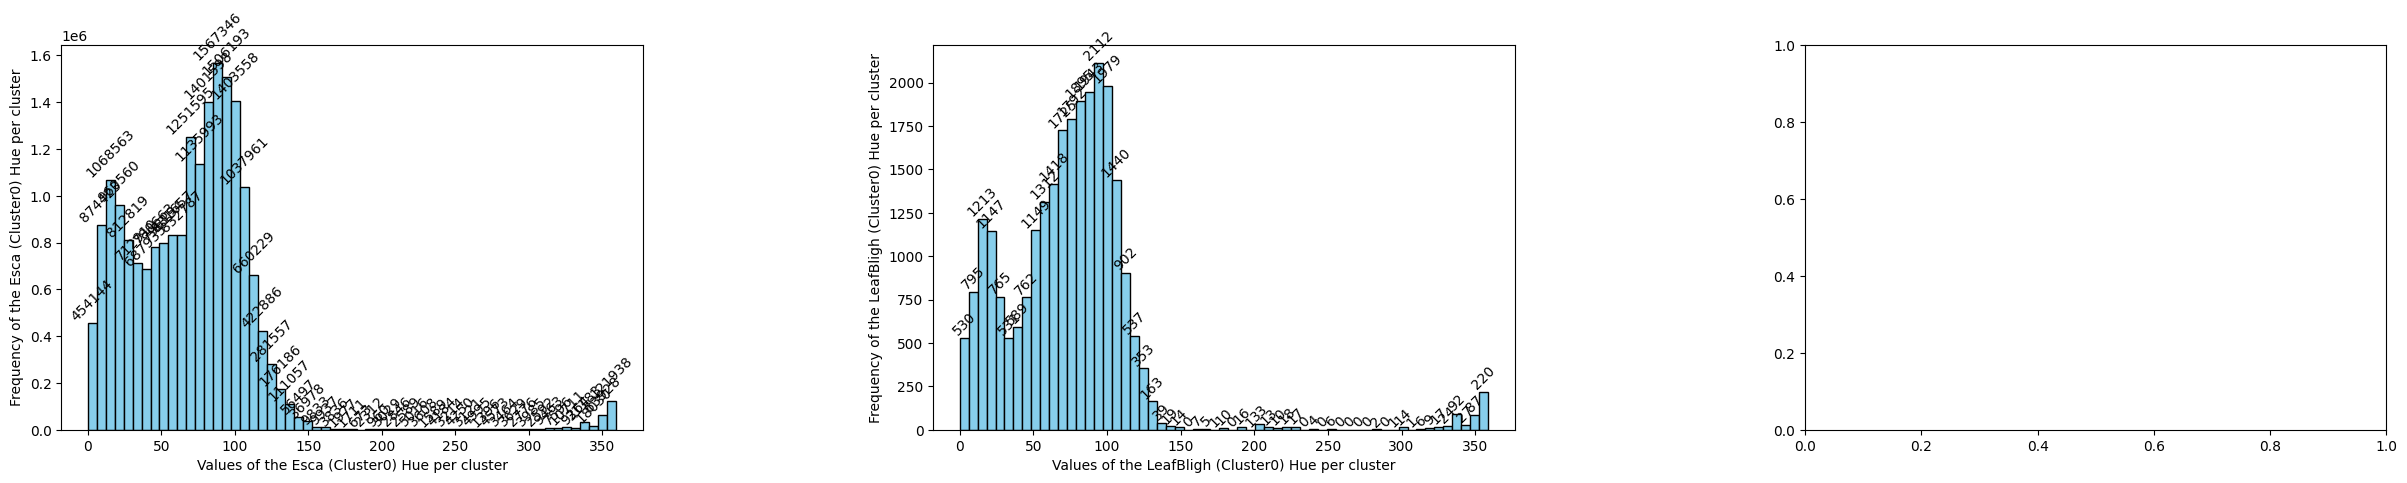

In [15]:
draw_histogram_abs(data_hue[0][0]  , data_hue[1][0], data_hue[2][0], 6, "Hue per cluster", "BlackRot (Cluster0)", "Esca (Cluster0)", "LeafBligh (Cluster0)")

<Figure size 1600x800 with 0 Axes>

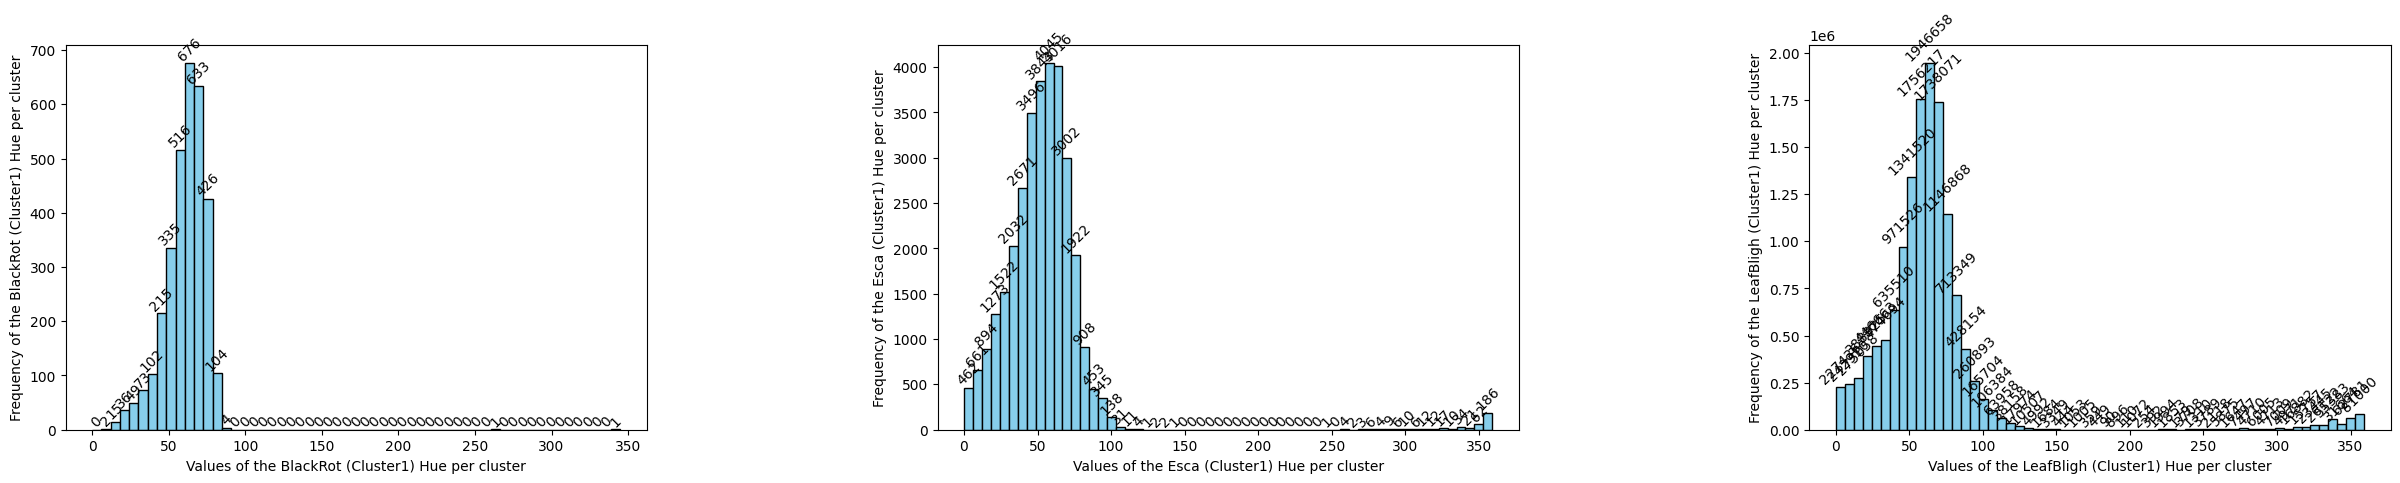

In [21]:
draw_histogram_abs(data_hue[0][1]  , data_hue[1][1], data_hue[2][1], 6, "Hue per cluster", "BlackRot (Cluster1)", "Esca (Cluster1)", "LeafBligh (Cluster1)")

<Figure size 1600x800 with 0 Axes>

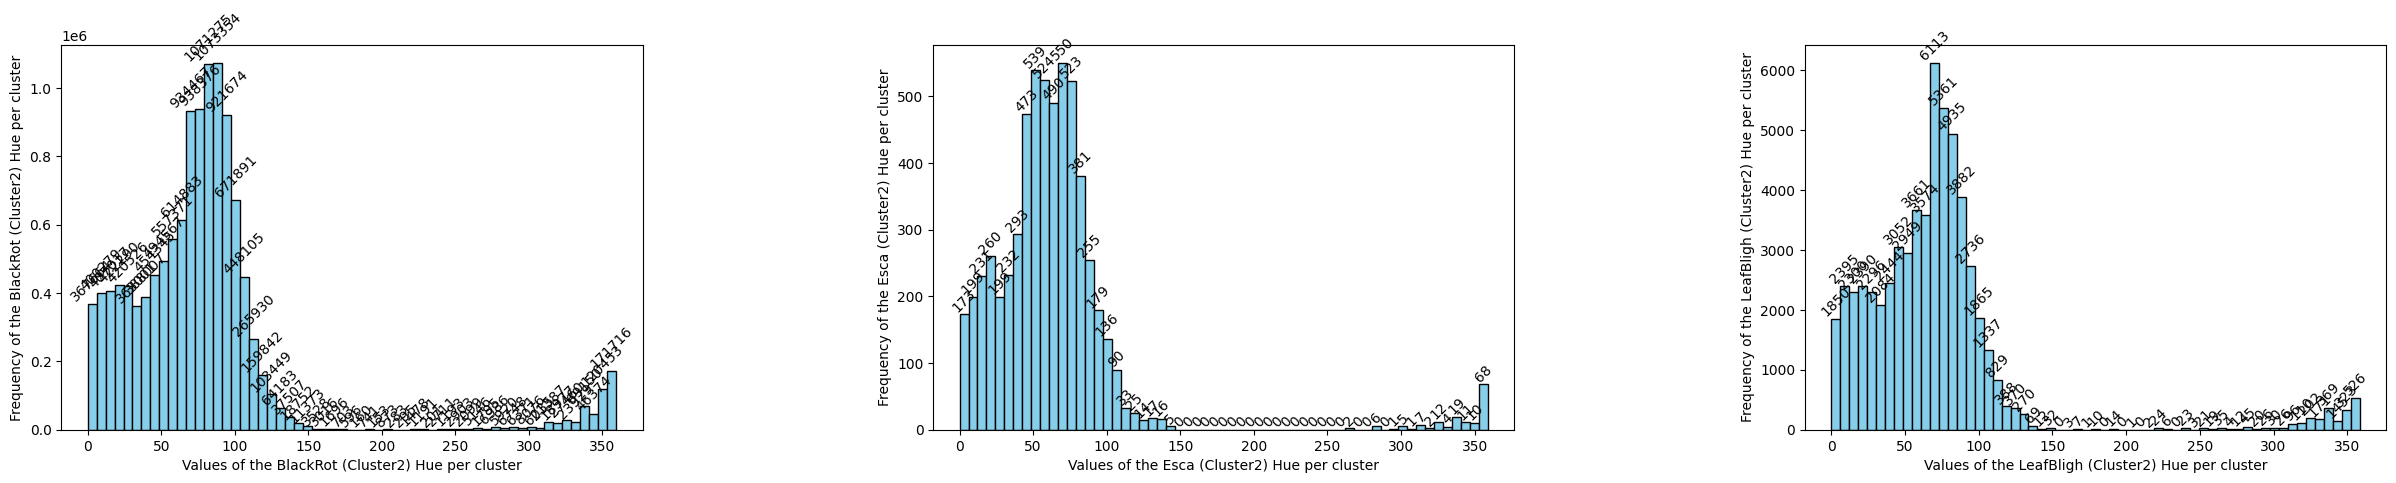

In [23]:
draw_histogram_abs(data_hue[0][2]  , data_hue[1][2], data_hue[2][2], 6, "Hue per cluster", "BlackRot (Cluster2)", "Esca (Cluster2)", "LeafBligh (Cluster2)")

### Histogramas per classe

In [85]:
import copy

new_data_hue = copy.deepcopy(data_hue)
new_data_hue[0][0] = data_hue[0][2]  
new_data_hue[0][1] = data_hue[0][0]  
new_data_hue[0][2] = data_hue[0][1]  
new_data_hue[1][0] = data_hue[1][2]  
new_data_hue[1][1] = data_hue[1][0]  
new_data_hue[1][2] = data_hue[1][1]  
new_data_hue[2][0] = data_hue[2][2]  
new_data_hue[2][1] = data_hue[2][0]  
new_data_hue[2][2] = data_hue[2][1]  

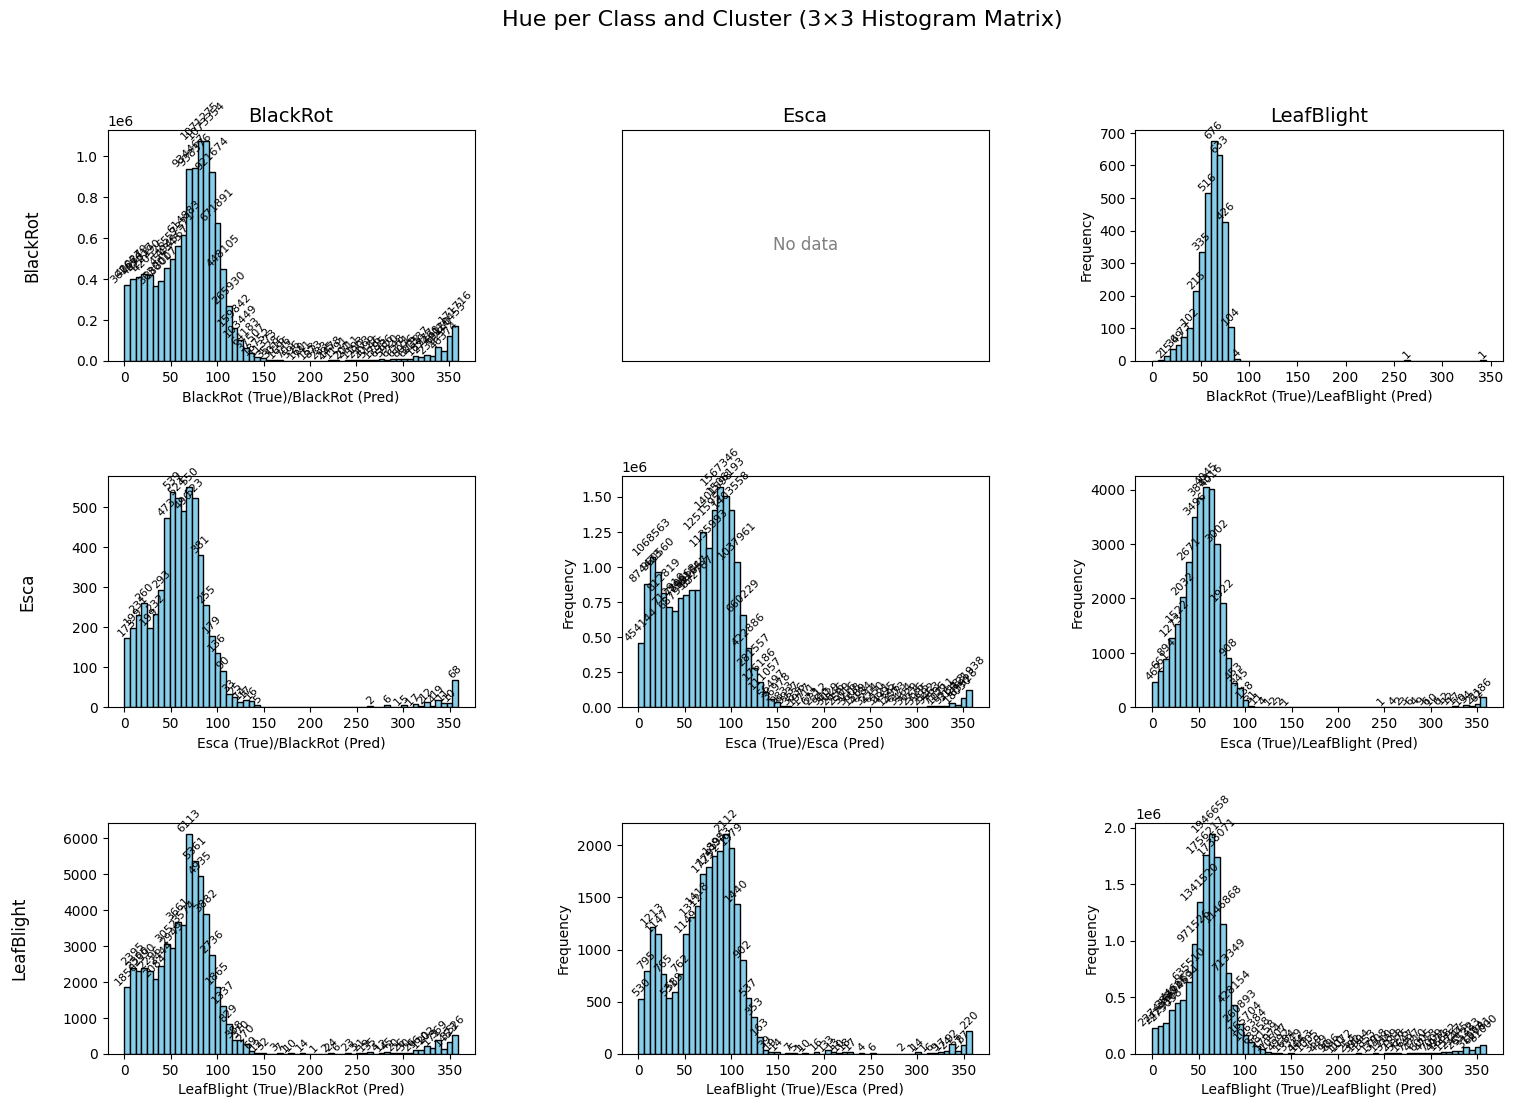

In [90]:
draw_histogram_abs_3x3_matrix(
    new_data_hue,
    bin_interval=6,
    class_labels=["BlackRot", "Esca", "LeafBlight"],
    cluster_labels=["BlackRot", "Esca", "LeafBlight"]
)

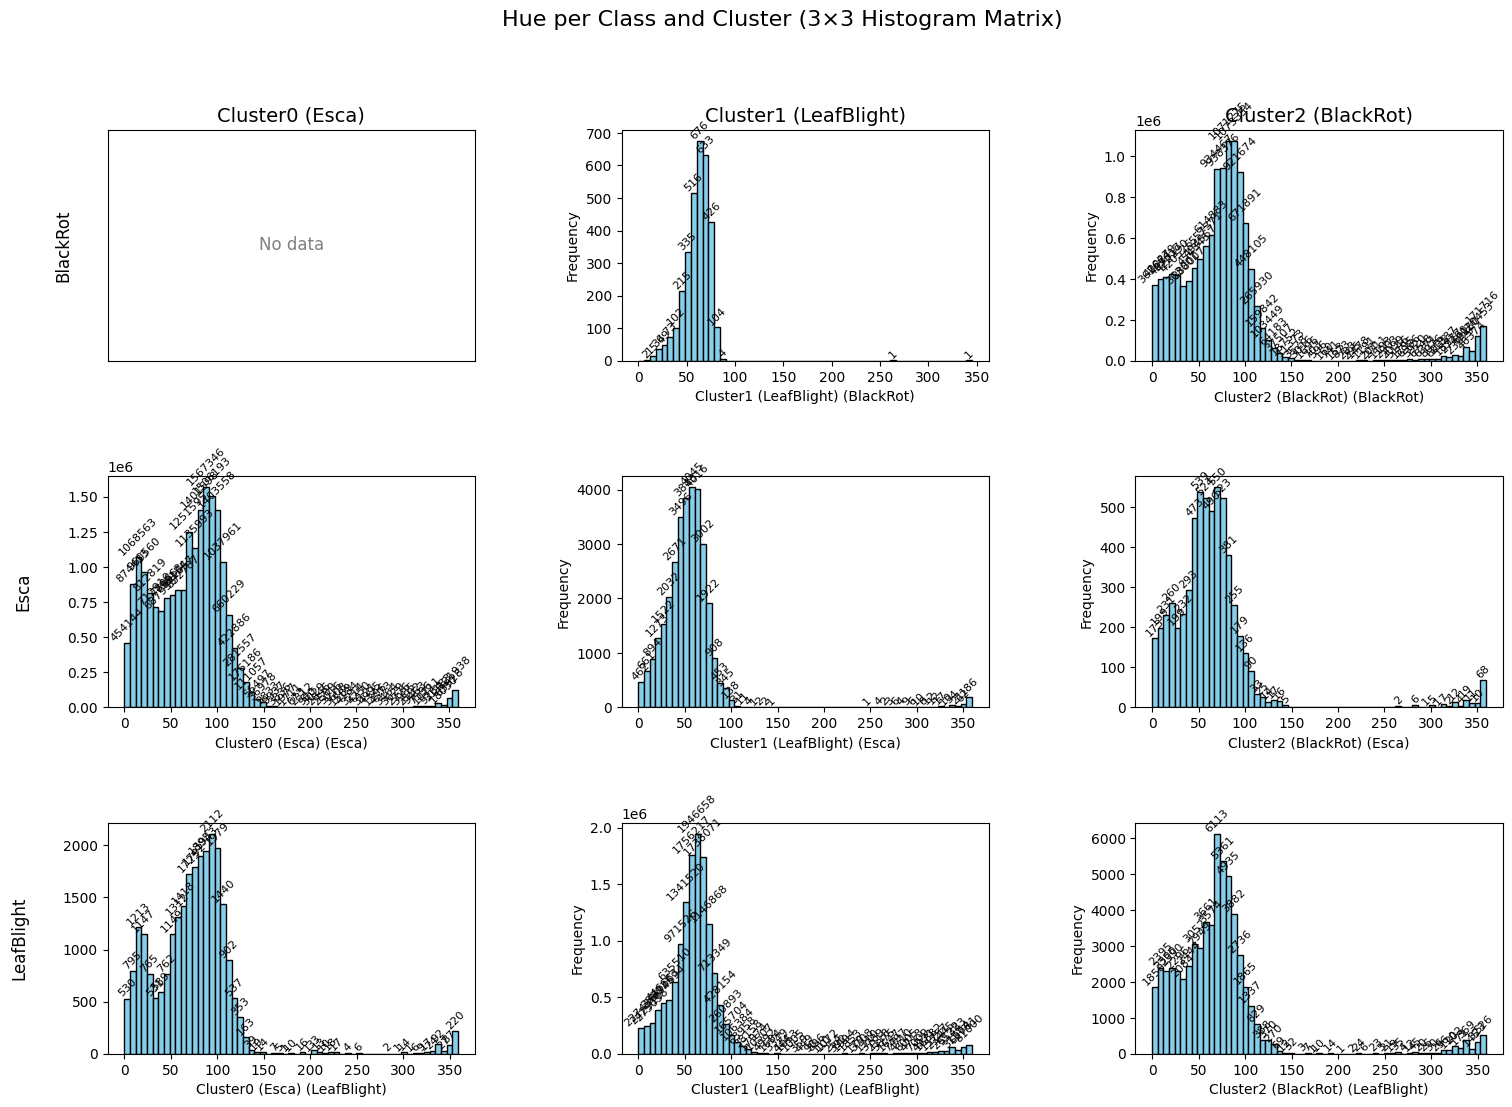

In [ ]:
draw_histogram_abs_3x3_matrix(
    data_hue,
    bin_interval=6,
    class_labels=["BlackRot", "Esca", "LeafBlight"],
    cluster_labels=["Esca", "LeafBlight", "BlackRot"]
)


<Figure size 1600x800 with 0 Axes>

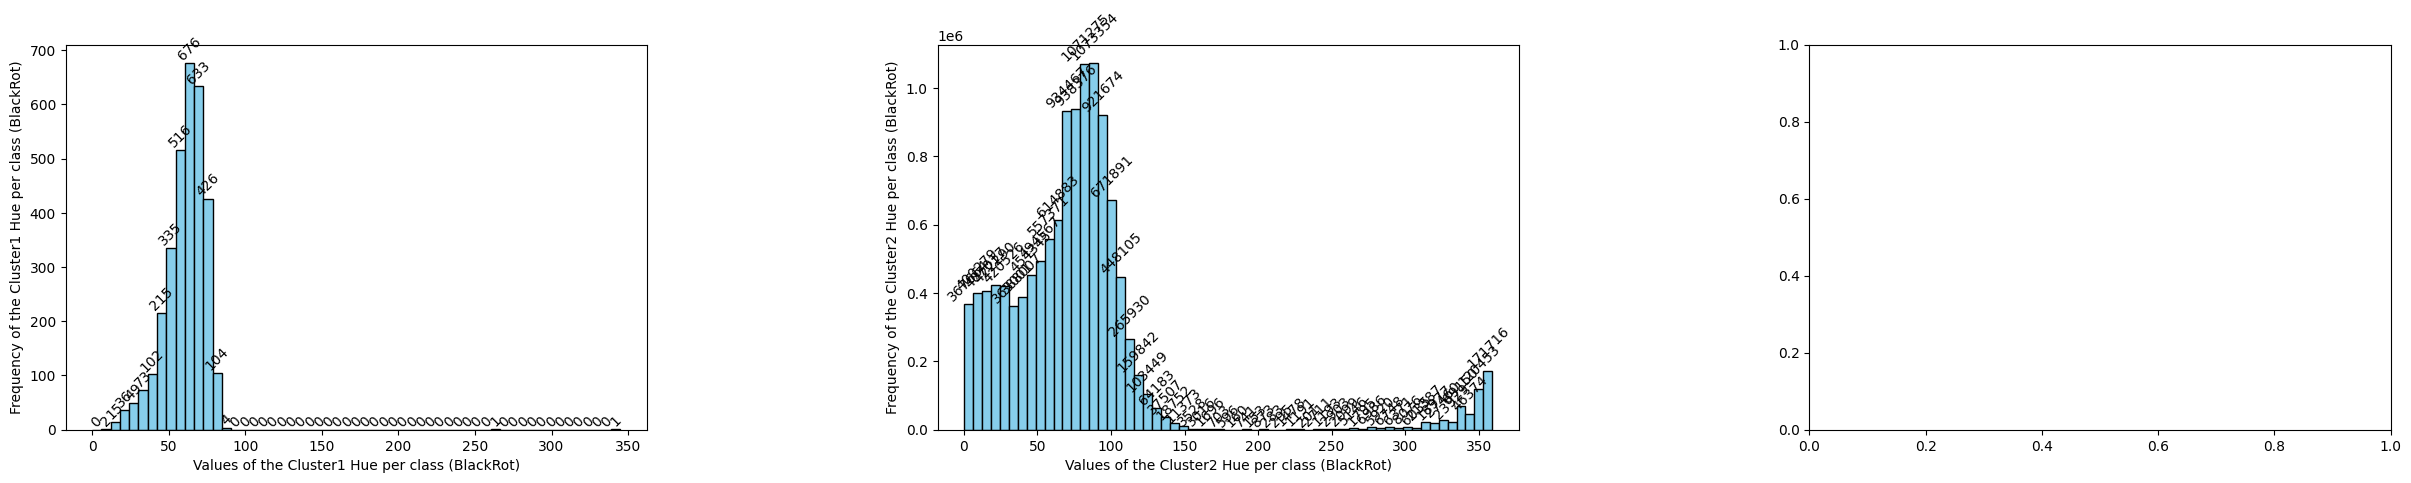

<Figure size 1600x800 with 0 Axes>

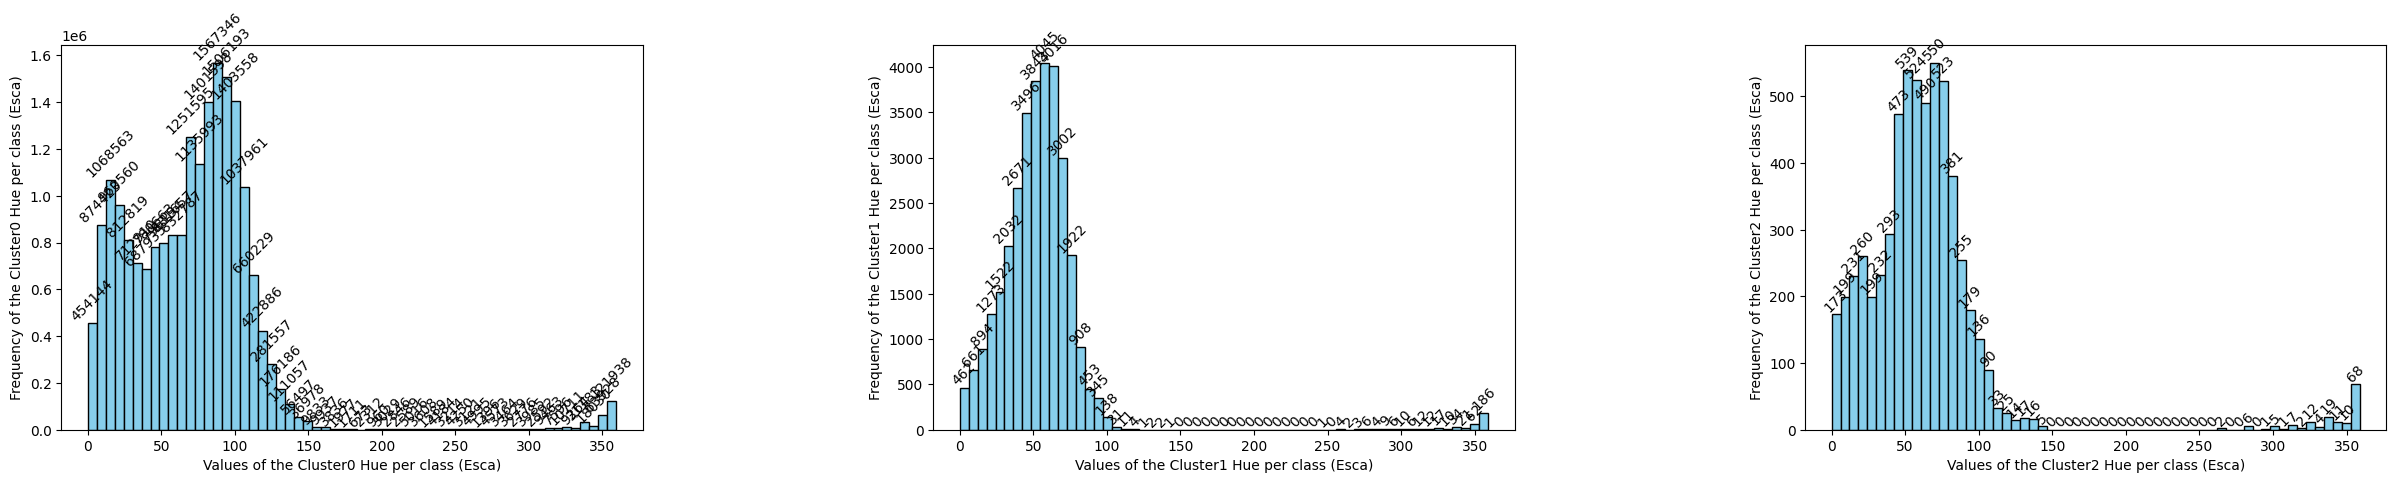

<Figure size 1600x800 with 0 Axes>

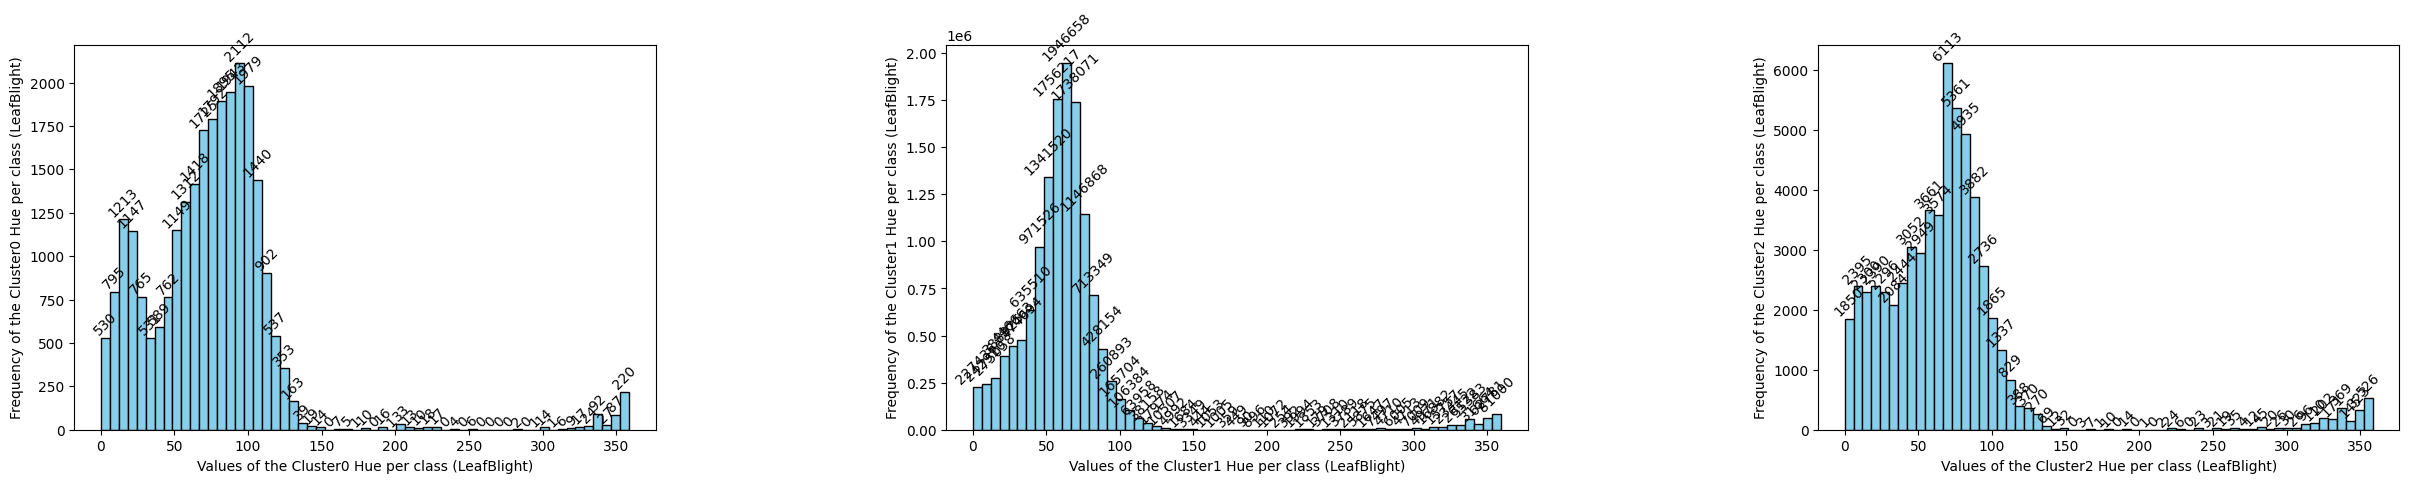

In [35]:
draw_histogram_abs(data_hue[0][0]  , data_hue[0][1], data_hue[0][2], 6, "Hue per class (BlackRot)", "Cluster0", "Cluster1", "Cluster2")
draw_histogram_abs(data_hue[1][0]  , data_hue[1][1], data_hue[1][2], 6, "Hue per class (Esca)", "Cluster0", "Cluster1", "Cluster2")
draw_histogram_abs(data_hue[2][0], data_hue[2][1], data_hue[2][2], 6, "Hue per class (LeafBlight)", "Cluster0", "Cluster1", "Cluster2")

### Brightness per cluster

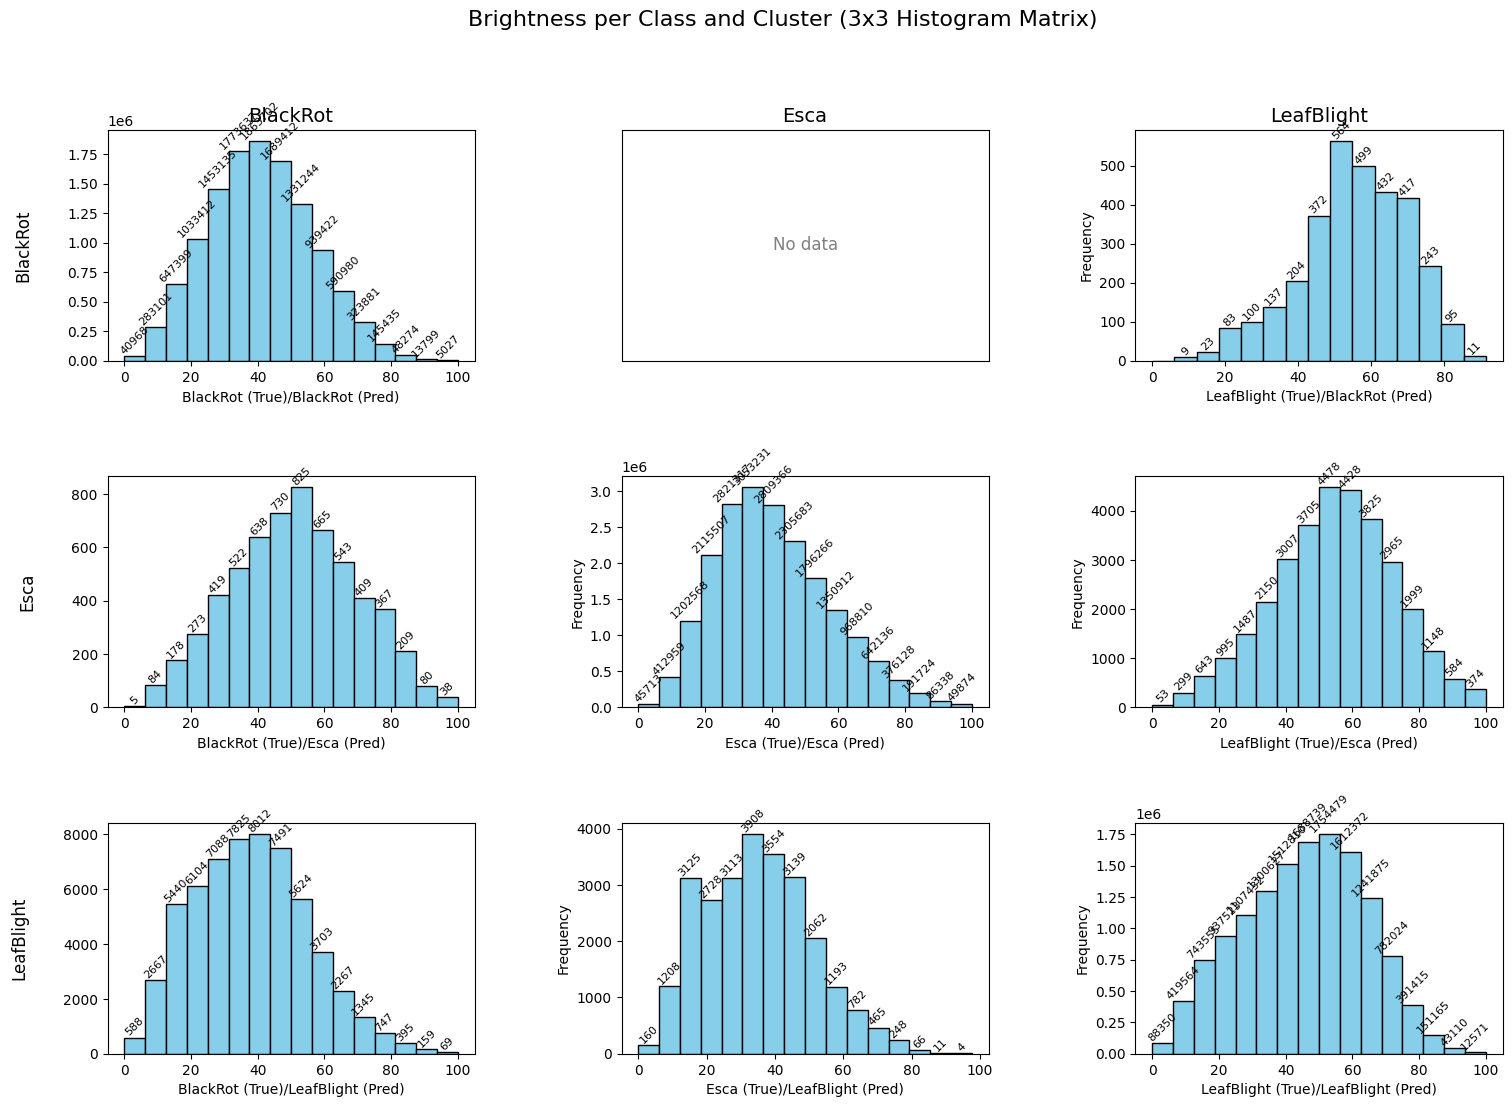

In [87]:
import copy

new_data_brightness = copy.deepcopy(data_brightness)
new_data_brightness[0][0] = data_brightness[0][2]  
new_data_brightness[0][1] = data_brightness[0][0]  
new_data_brightness[0][2] = data_brightness[0][1]  
new_data_brightness[1][0] = data_brightness[1][2]  
new_data_brightness[1][1] = data_brightness[1][0]  
new_data_brightness[1][2] = data_brightness[1][1]  
new_data_brightness[2][0] = data_brightness[2][2]  
new_data_brightness[2][1] = data_brightness[2][0]  
new_data_brightness[2][2] = data_brightness[2][1] 


draw_histogram_abs_3x3_matrix(
    new_data_brightness,
    bin_interval=6,
    class_labels=["BlackRot", "Esca", "LeafBlight"],
    cluster_labels=["BlackRot", "Esca", "LeafBlight"],
    title="Brightness per Class and Cluster (3x3 Histogram Matrix)"
)

<Figure size 1600x800 with 0 Axes>

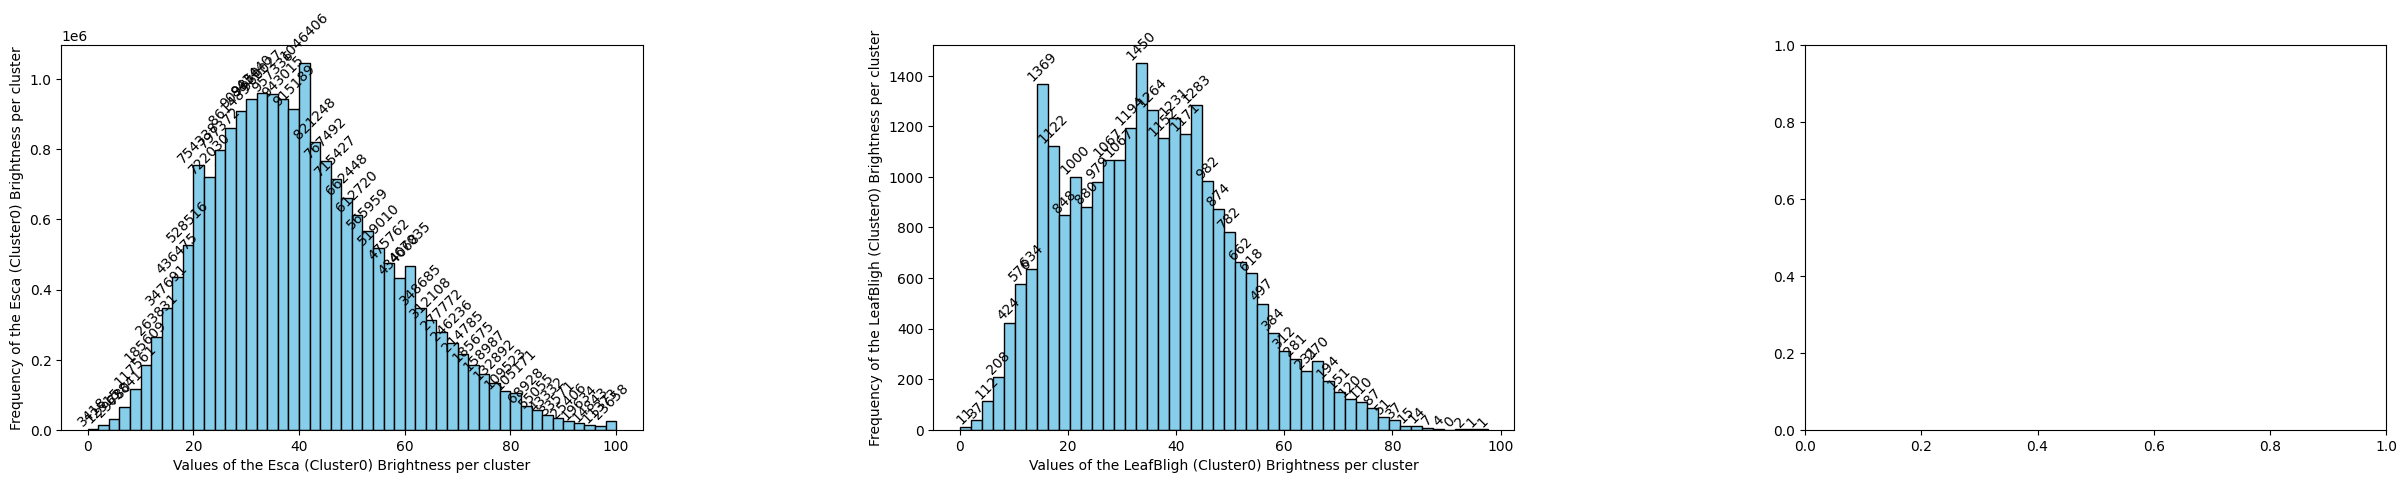

<Figure size 1600x800 with 0 Axes>

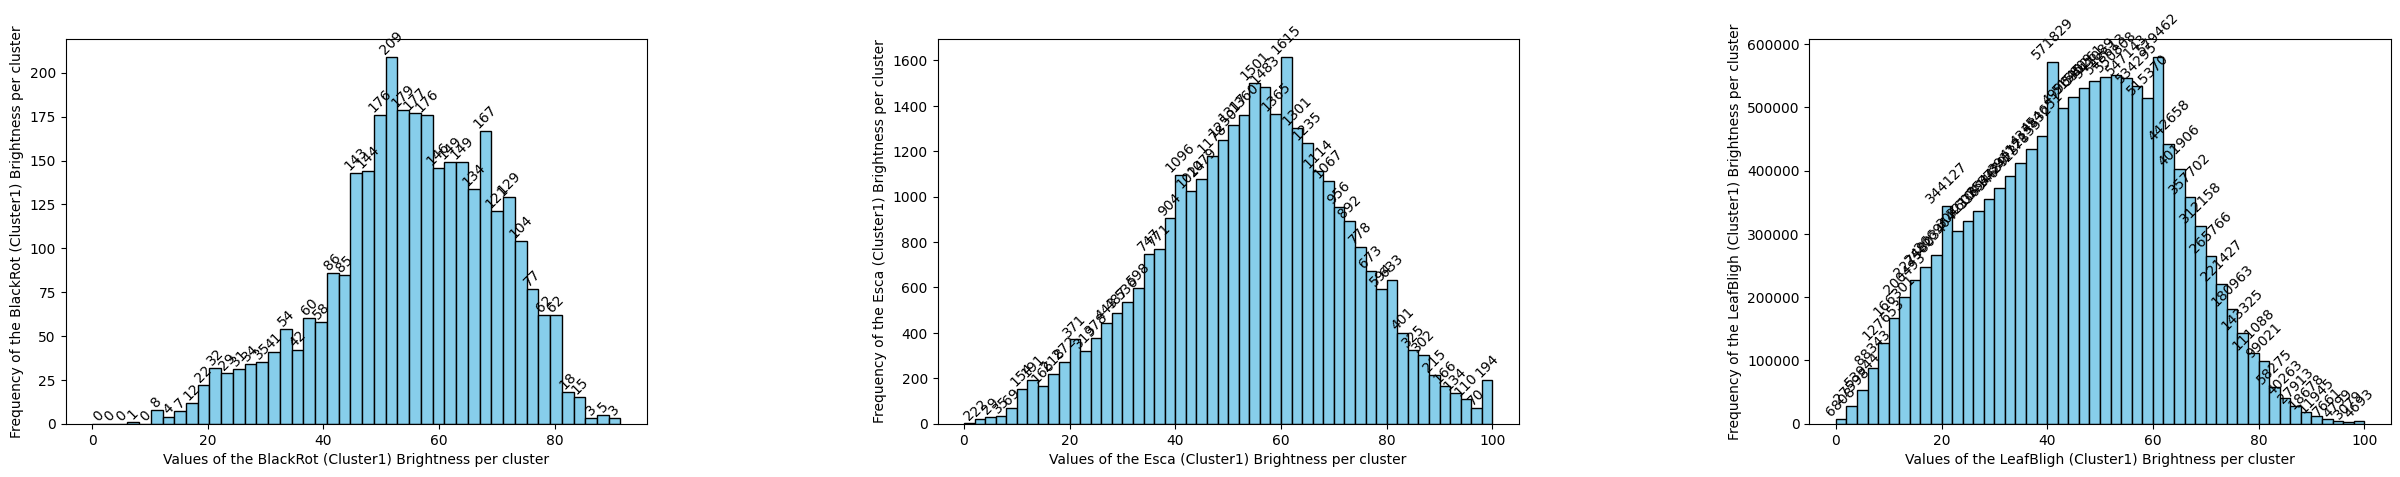

<Figure size 1600x800 with 0 Axes>

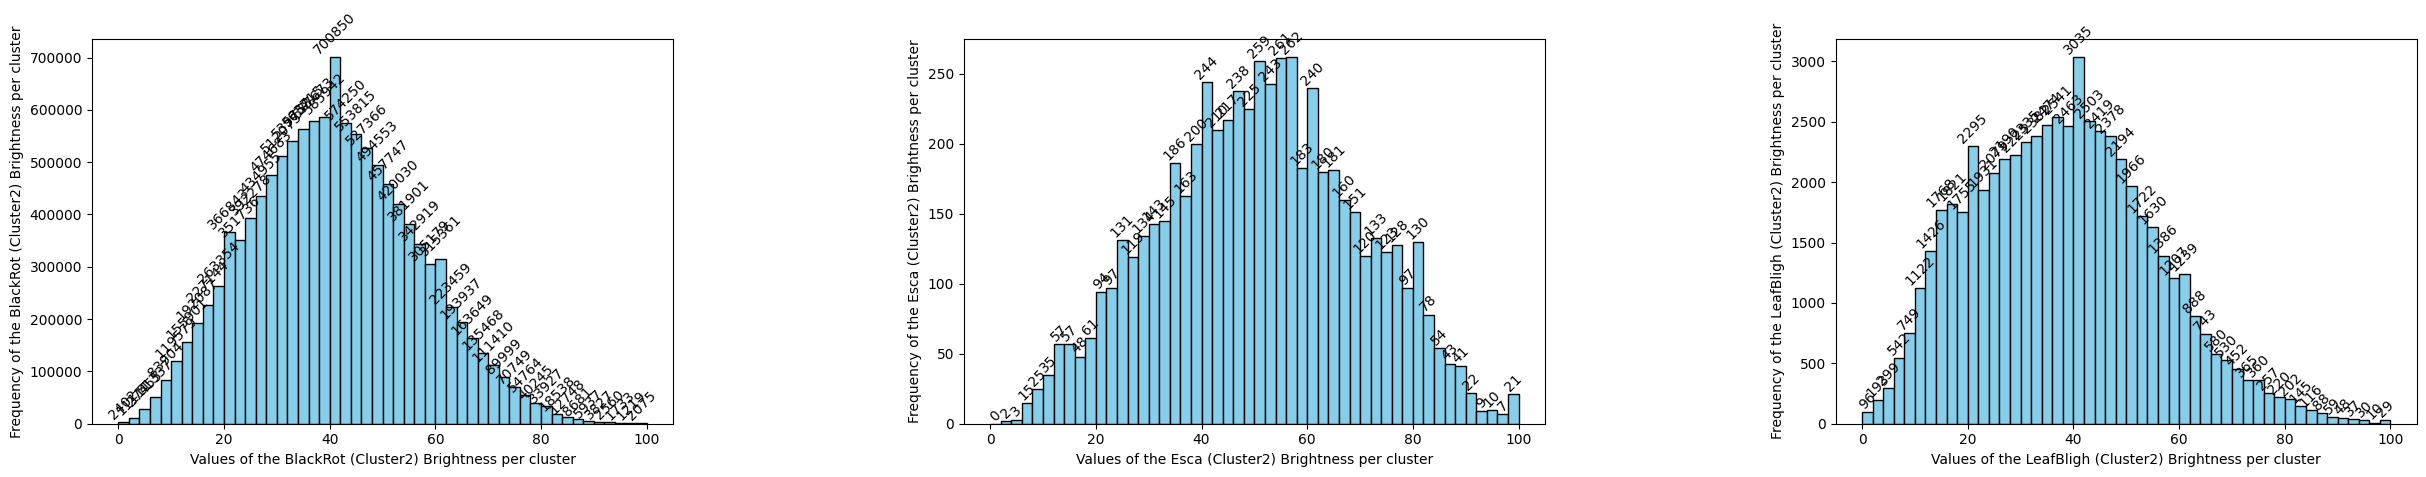

In [30]:
draw_histogram_abs(data_brightness[0][0], data_brightness[1][0], data_brightness[2][0], 2, "Brightness per cluster", "BlackRot (Cluster0)", "Esca (Cluster0)", "LeafBligh (Cluster0)")
draw_histogram_abs(data_brightness[0][1], data_brightness[1][1], data_brightness[2][1], 2, "Brightness per cluster", "BlackRot (Cluster1)", "Esca (Cluster1)", "LeafBligh (Cluster1)")
draw_histogram_abs(data_brightness[0][2], data_brightness[1][2], data_brightness[2][2], 2, "Brightness per cluster", "BlackRot (Cluster2)", "Esca (Cluster2)", "LeafBligh (Cluster2)")

### Brightness per class

<Figure size 1600x800 with 0 Axes>

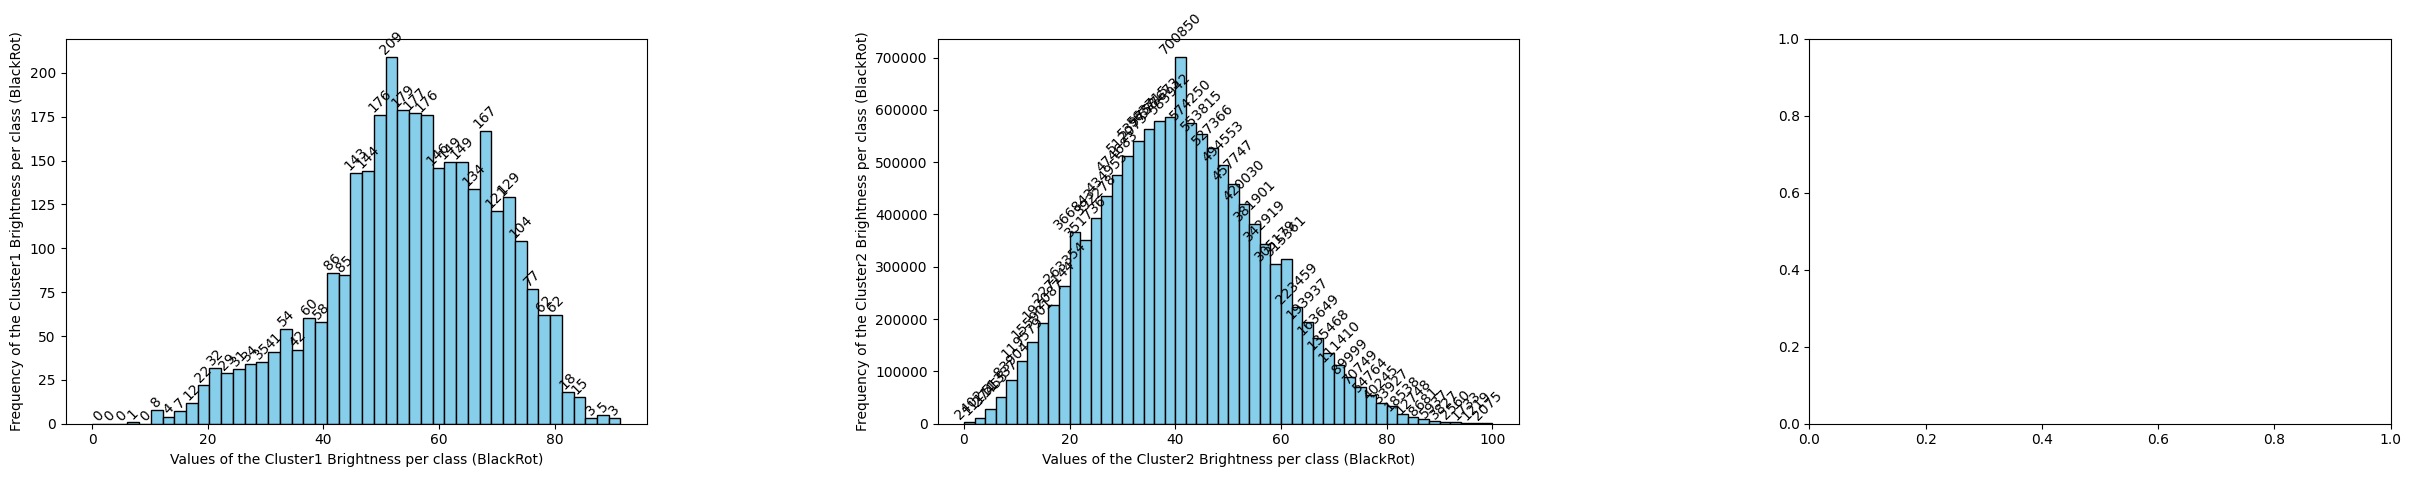

<Figure size 1600x800 with 0 Axes>

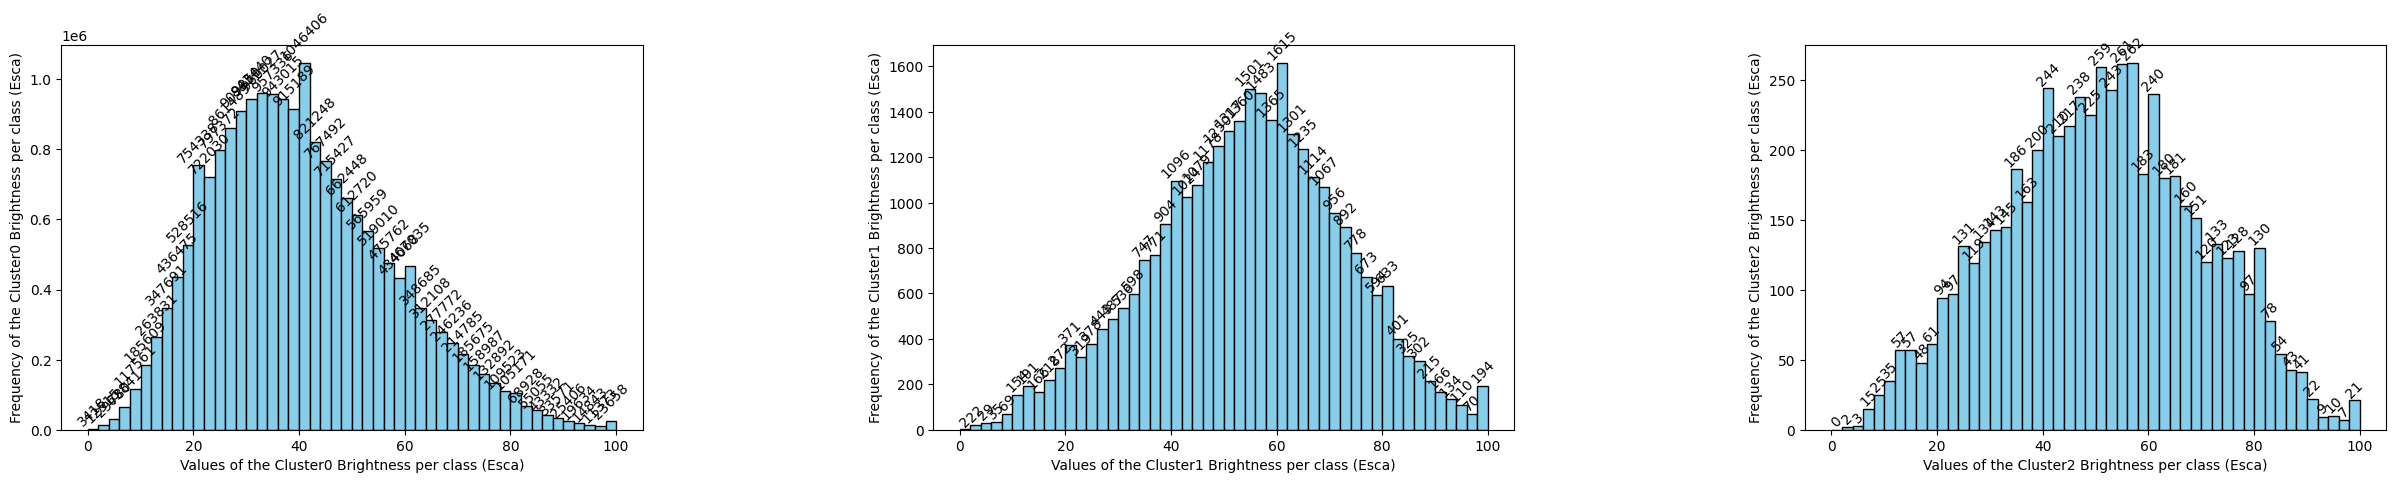

<Figure size 1600x800 with 0 Axes>

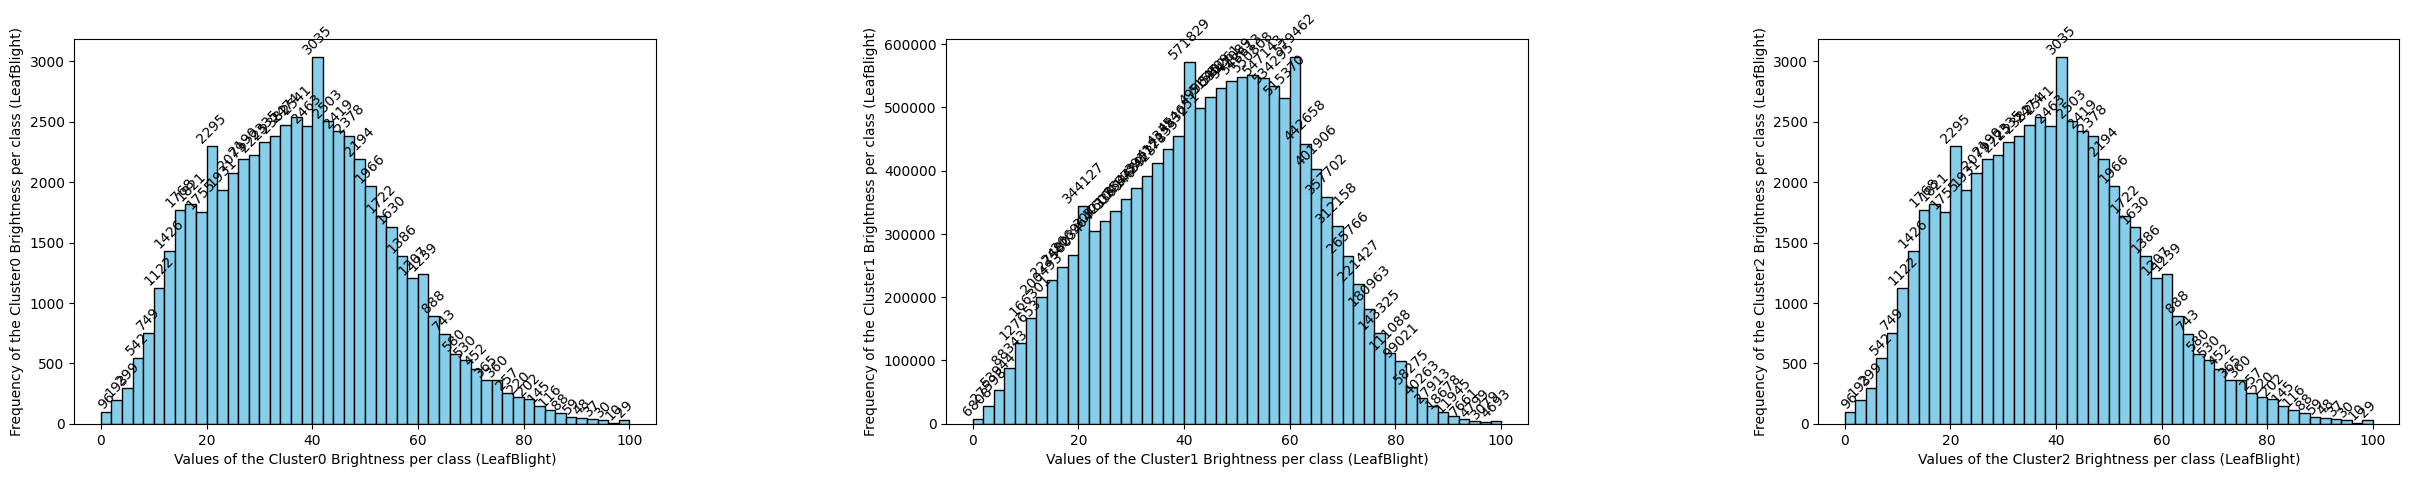

In [31]:
draw_histogram_abs(data_brightness[0][0], data_brightness[0][1], data_brightness[0][2], 2, "Brightness per class (BlackRot)", "Cluster0", "Cluster1", "Cluster2")
draw_histogram_abs(data_brightness[1][0], data_brightness[1][1], data_brightness[1][2], 2, "Brightness per class (Esca)", "Cluster0", "Cluster1", "Cluster2")
draw_histogram_abs(data_brightness[2][2], data_brightness[2][1], data_brightness[2][2], 2, "Brightness per class (LeafBlight)", "Cluster0", "Cluster1", "Cluster2")

### Saturation per cluster

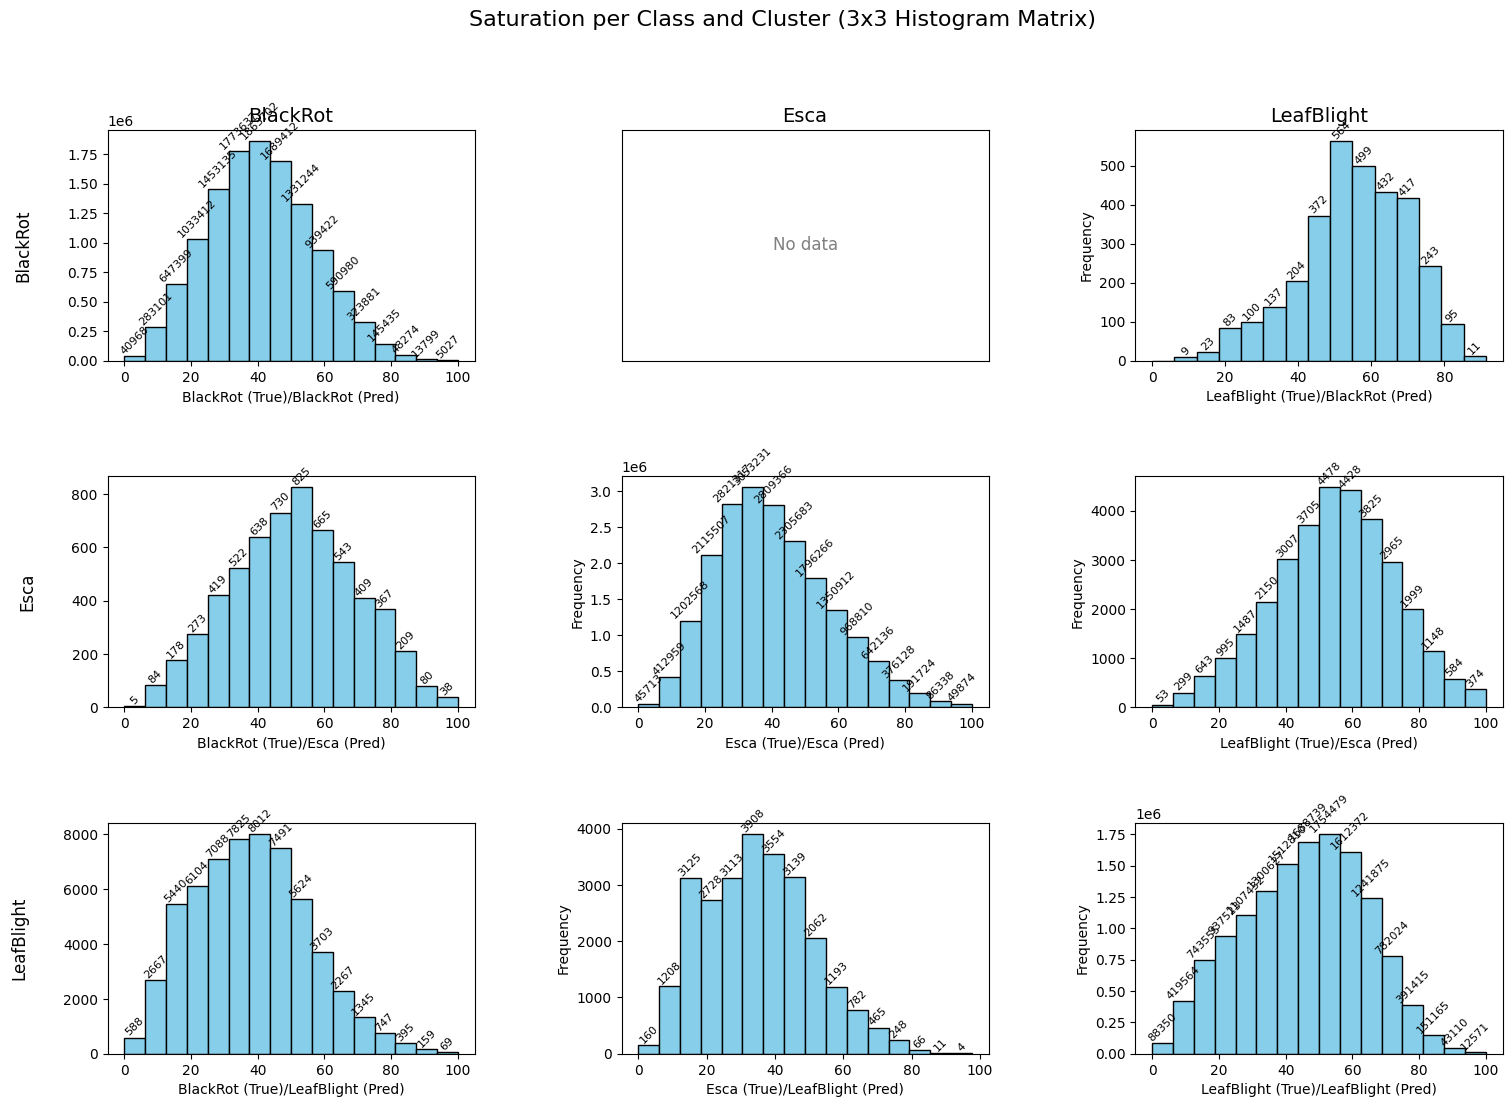

In [ ]:
import copy

new_data_saturation = copy.deepcopy(data_saturation)
new_data_saturation[0][0] = data_saturation[0][2]  
new_data_saturation[0][1] = data_saturation[0][0]  
new_data_saturation[0][2] = data_saturation[0][1]  
new_data_saturation[1][0] = data_saturation[1][2]  
new_data_saturation[1][1] = data_saturation[1][0]  
new_data_saturation[1][2] = data_saturation[1][1]  
new_data_saturation[2][0] = data_saturation[2][2]  
new_data_saturation[2][1] = data_saturation[2][0]  
new_data_saturation[2][2] = data_saturation[2][1] 


draw_histogram_abs_3x3_matrix(
    new_data_brightness,
    bin_interval=6,
    class_labels=["BlackRot", "Esca", "LeafBlight"],
    cluster_labels=["BlackRot", "Esca", "LeafBlight"],
    title="Saturation per Class and Cluster (3x3 Histogram Matrix)"
)

<Figure size 1600x800 with 0 Axes>

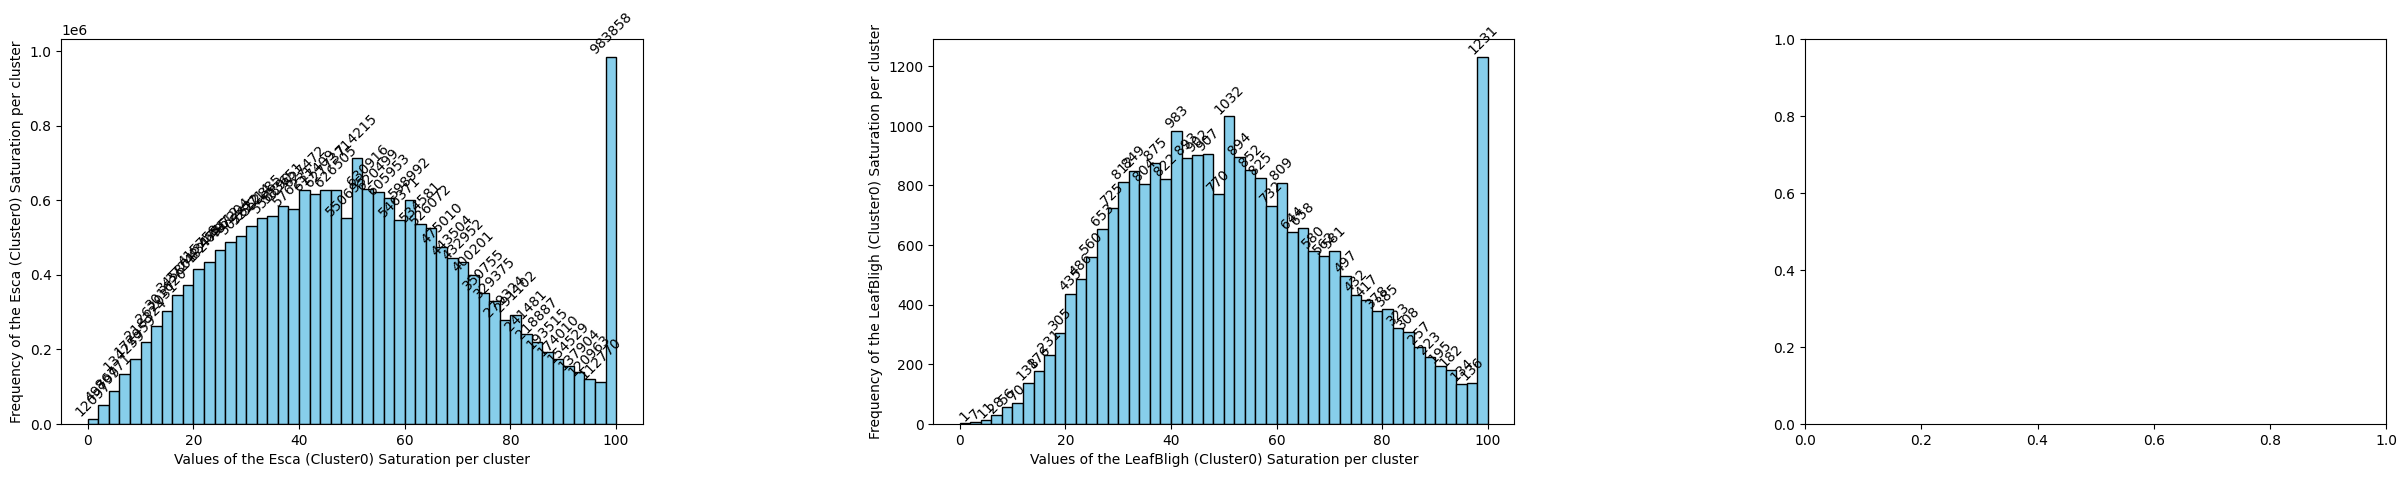

<Figure size 1600x800 with 0 Axes>

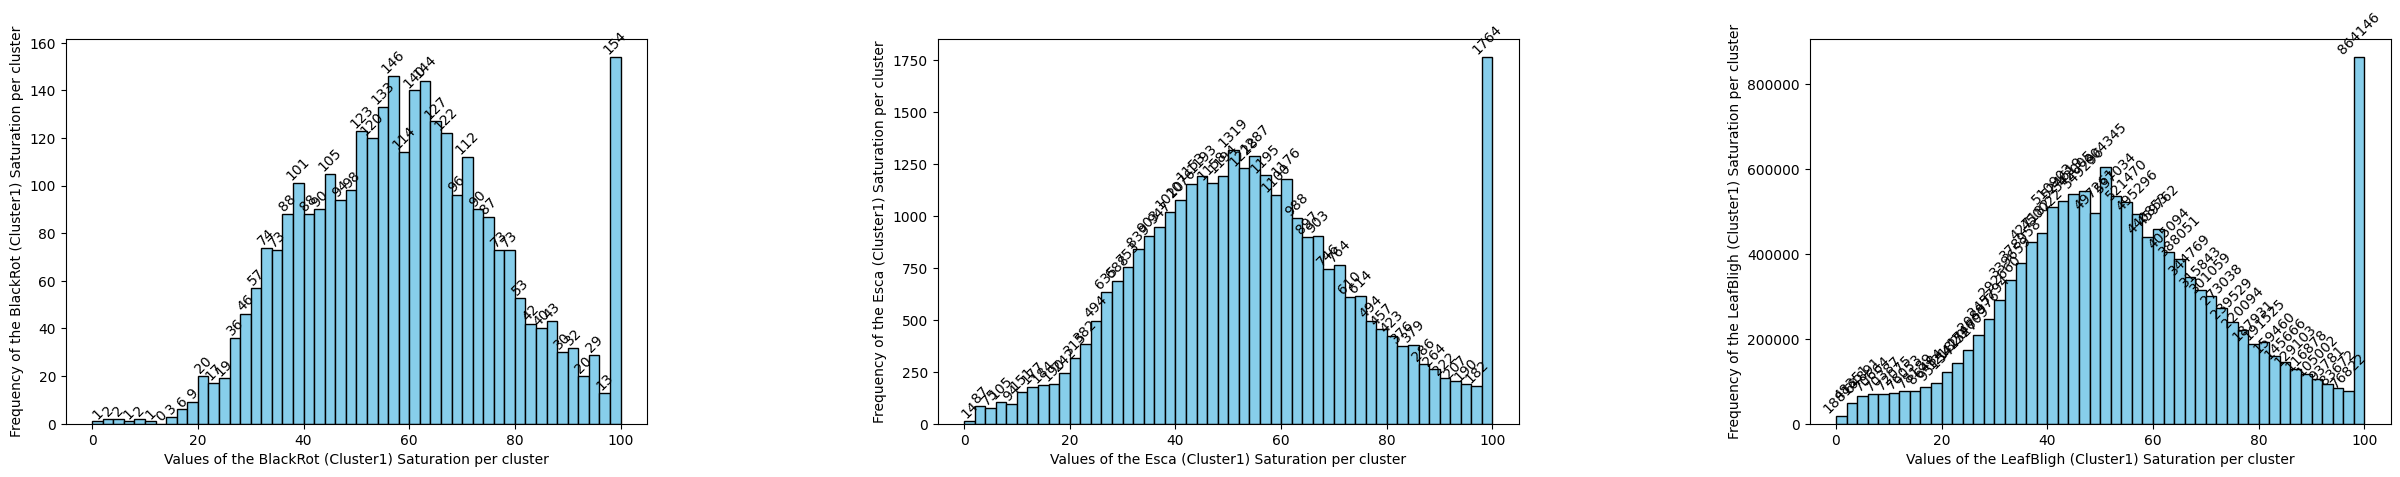

<Figure size 1600x800 with 0 Axes>

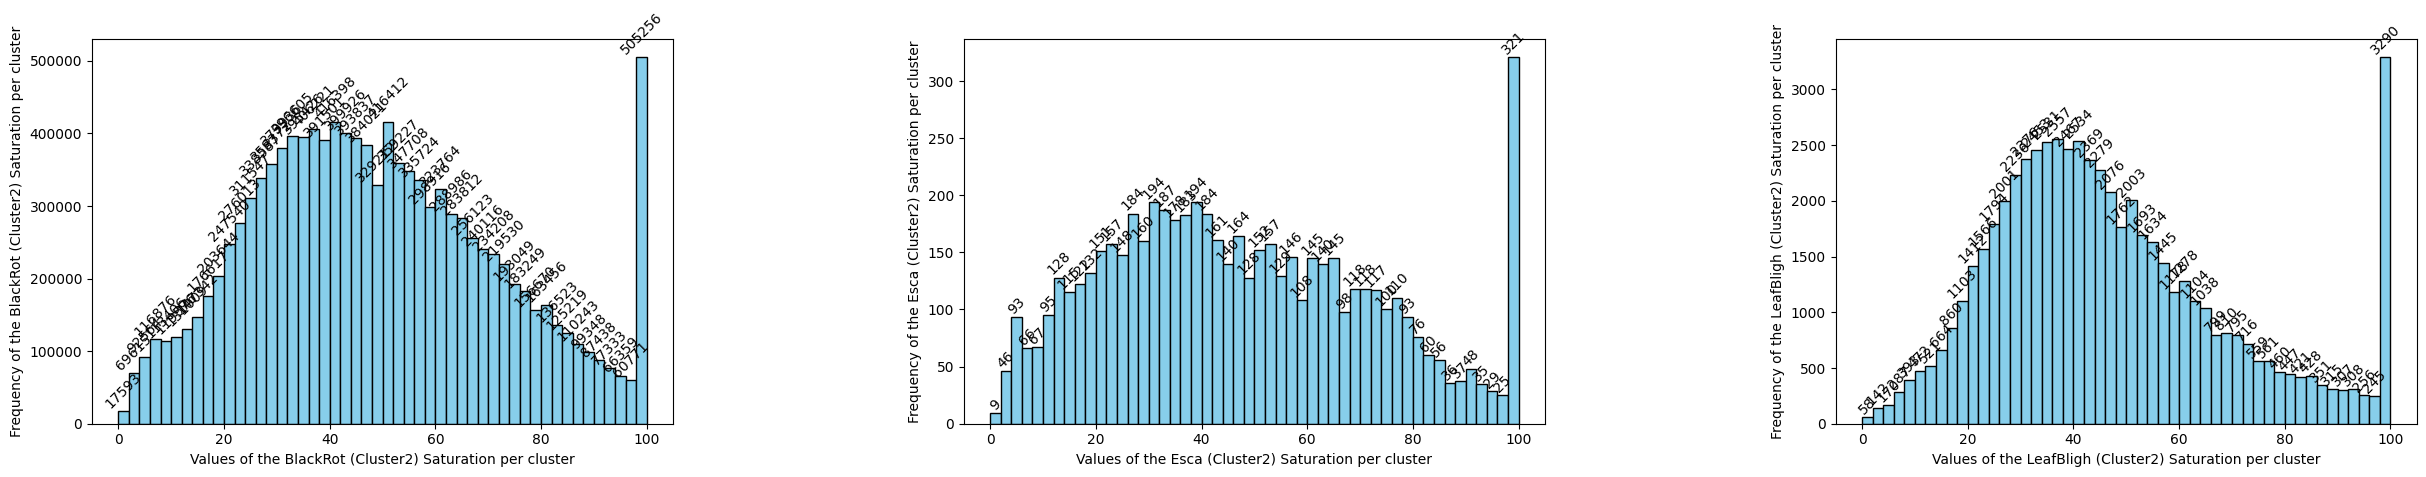

In [32]:
draw_histogram_abs(data_saturation[0][0], data_saturation[1][0], data_saturation[2][0], 2, "Saturation per cluster", "BlackRot (Cluster0)", "Esca (Cluster0)", "LeafBligh (Cluster0)")
draw_histogram_abs(data_saturation[0][1], data_saturation[1][1], data_saturation[2][1], 2, "Saturation per cluster", "BlackRot (Cluster1)", "Esca (Cluster1)", "LeafBligh (Cluster1)")
draw_histogram_abs(data_saturation[0][2], data_saturation[1][2], data_saturation[2][2], 2, "Saturation per cluster", "BlackRot (Cluster2)", "Esca (Cluster2)", "LeafBligh (Cluster2)")

### Saturation per class

<Figure size 1600x800 with 0 Axes>

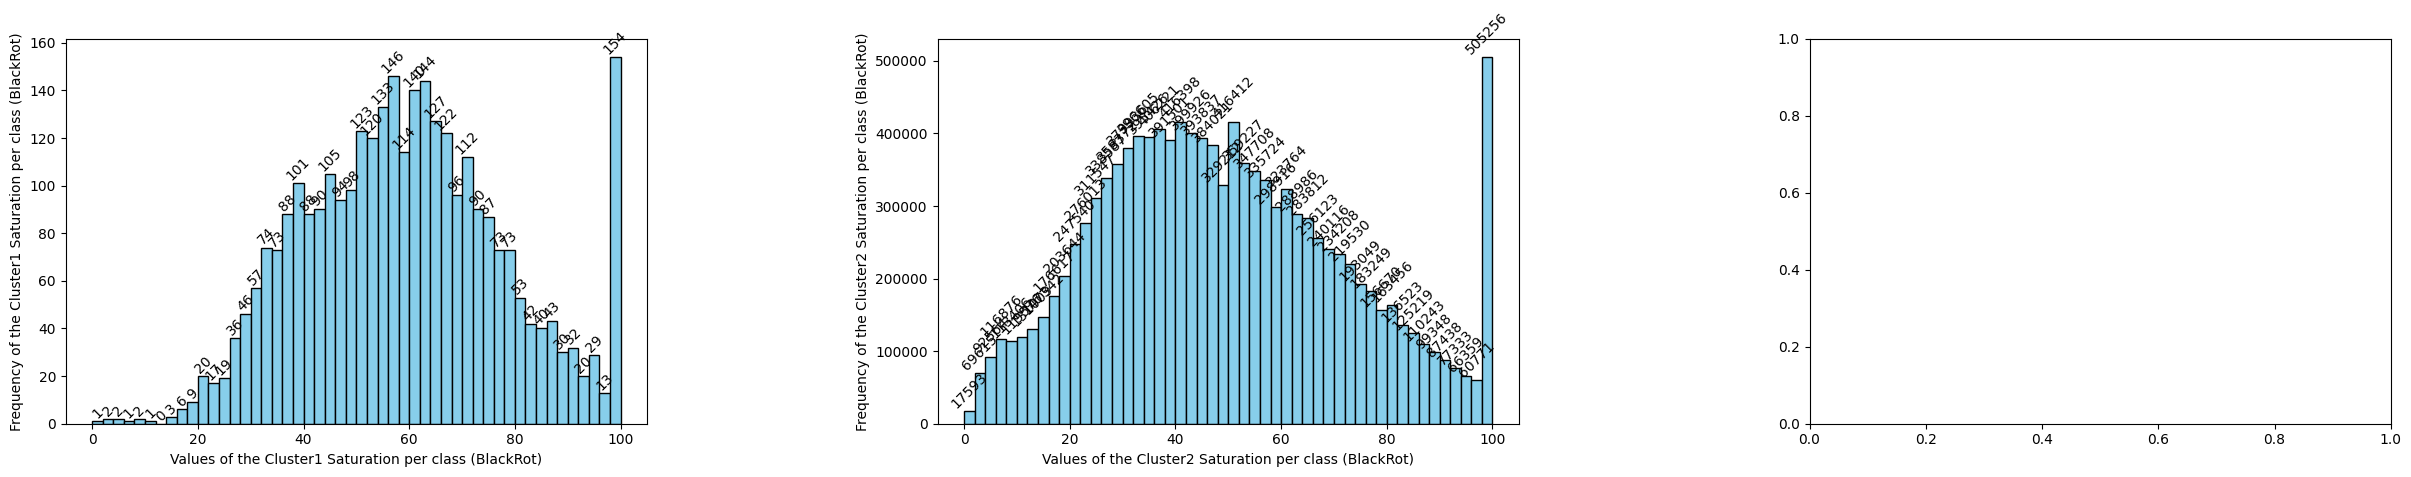

<Figure size 1600x800 with 0 Axes>

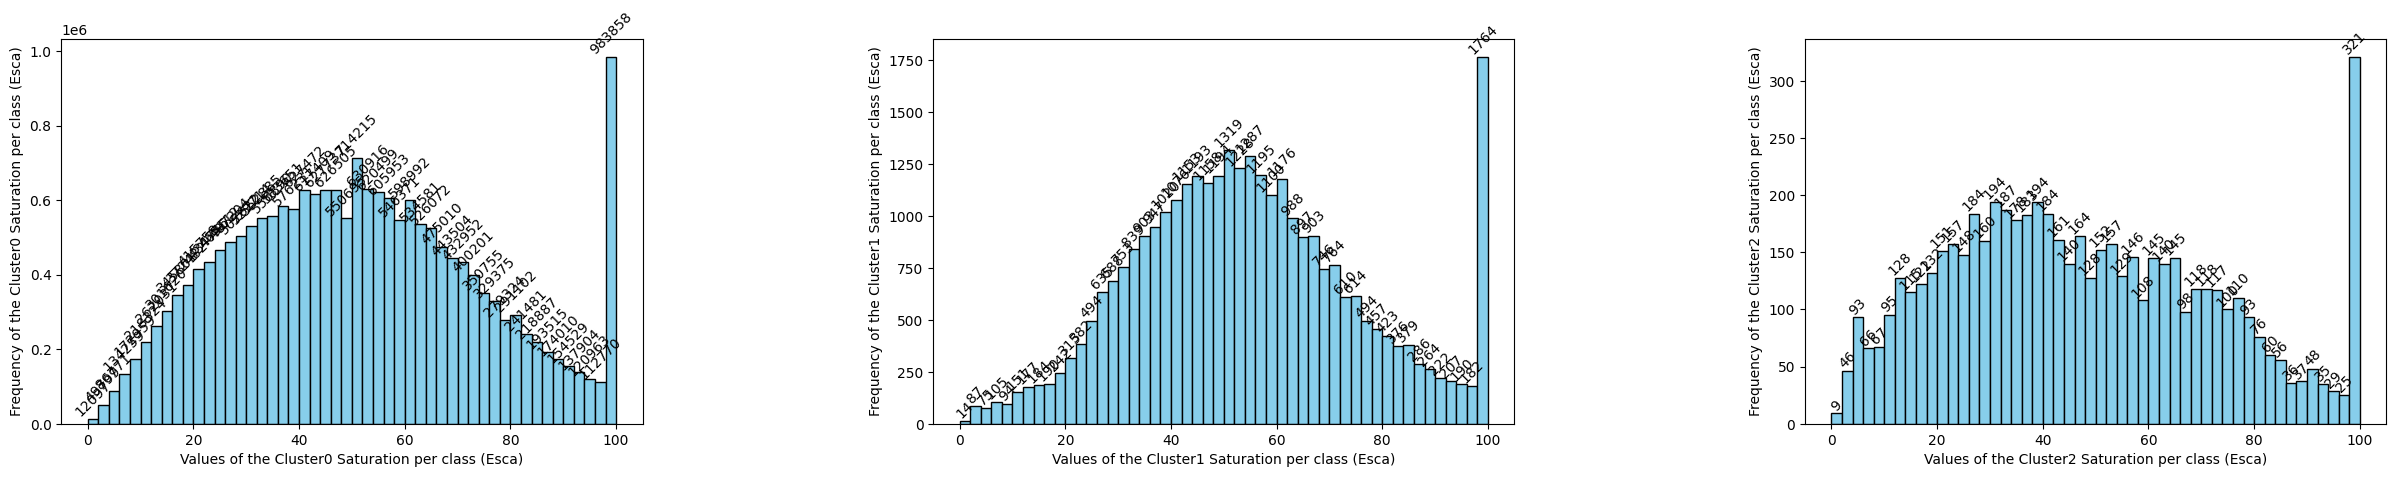

<Figure size 1600x800 with 0 Axes>

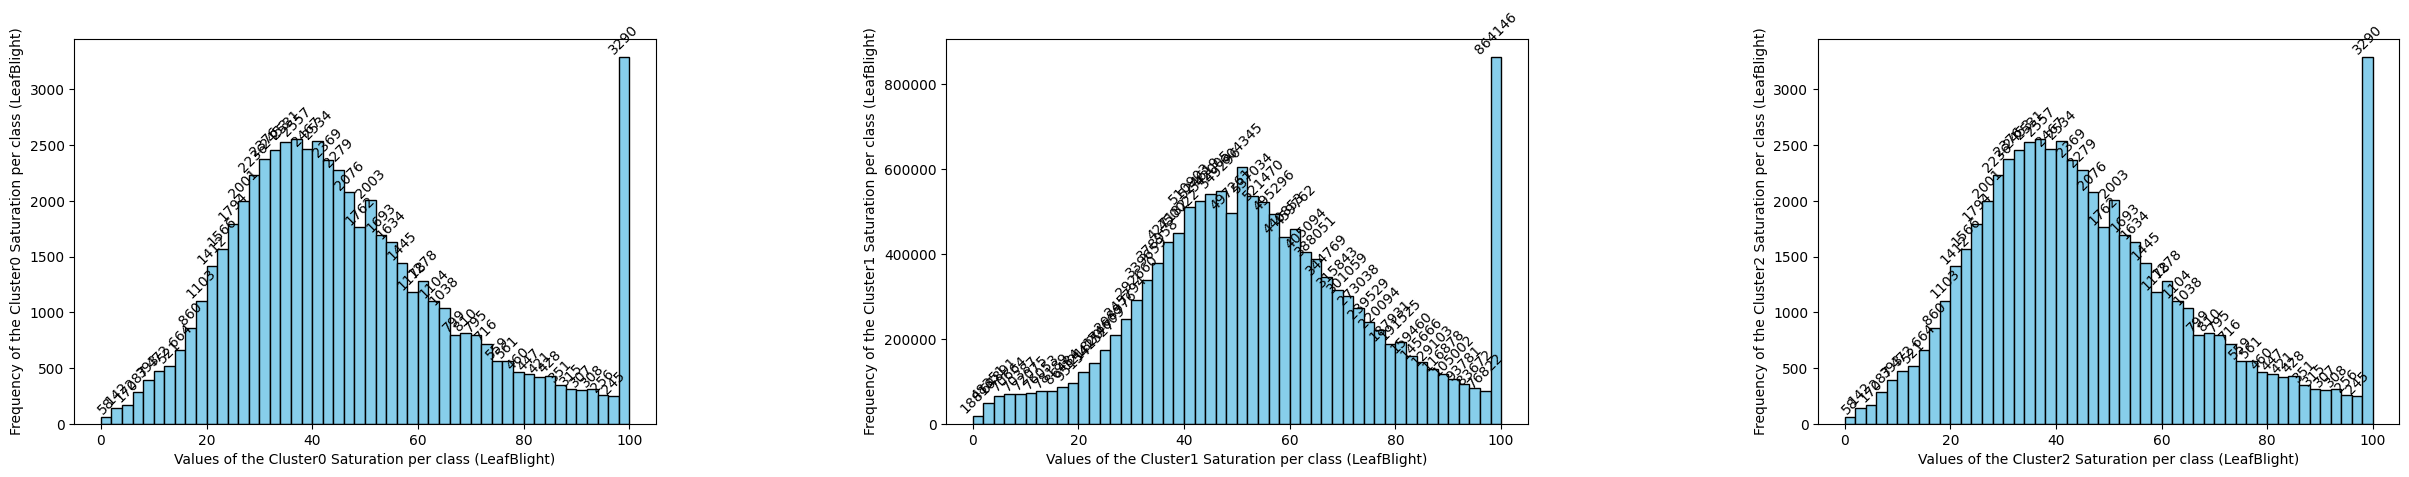

In [33]:
draw_histogram_abs(data_saturation[0][0], data_saturation[0][1], data_saturation[0][2], 2, "Saturation per class (BlackRot)", "Cluster0", "Cluster1", "Cluster2")
draw_histogram_abs(data_saturation[1][0], data_saturation[1][1], data_saturation[1][2], 2, "Saturation per class (Esca)", "Cluster0", "Cluster1", "Cluster2")
draw_histogram_abs(data_saturation[2][2], data_saturation[2][1], data_saturation[2][2], 2, "Saturation per class (LeafBlight)", "Cluster0", "Cluster1", "Cluster2")